In [5]:
import sys
from src.E7 import E7 as E7_ricardo
from src.E9 import E9 as E9_ricardo
import numpy as np
import time
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

plt.rcParams.update({
    "mathtext.fontset": "cm",        # Computer Modern for math
    "font.family": "serif",
    "font.serif": ["cmr10"],         # Computer Modern for normal text
    "axes.formatter.use_mathtext": True,  # needed so cmr10 draws minus signs and 10^x ticks correctly
})

def do_cov_sub_plot(ax, normalize, title, ax_index, C_order, ell_range, ell_p_range):
        
        l_min = ell_range[0]
        l_max = ell_range[1]
        lp_min = ell_p_range[0]
        lp_max = ell_p_range[1]
        C_order = np.where(np.abs(C_order) < 1e-12, 1e-12, np.abs(C_order))

        ell_to_s_map = np.array([l * (l+1) - l - l_min**2  for l in range(l_min, l_max+1)])
        ellp_to_s_map = np.array([l * (l+1) - l - lp_min**2  for l in range(lp_min, lp_max+1)])

        axim = ax.imshow(C_order.T, cmap='inferno', norm=LogNorm(), origin='lower',  interpolation = 'nearest')

        if lp_max > 50 or l_max > 50:
            ax.set_title(str(ax_index+5), weight='bold', fontsize='60')
        else:
            #ax.set_title(str(ax_index+1), weight='bold', fontsize='20')
            ax.set_title(rf'{title}', fontsize='60')


        if ax_index == 0 or ax_index == 3 or ax_index == 6:
             ax.set_ylabel(r"$\ell'$", fontsize=60)

             ax.set_yticks(ellp_to_s_map-0.5)
             ax.tick_params(axis='y', labelsize=18)
             ax.set_yticklabels(np.arange(lp_min, lp_max+1))
             ax.tick_params(which='major', length=10, width=3, labelsize=50)

        else:
             ax.set_yticks(ellp_to_s_map-0.5)
             ax.set_yticklabels([])          
             ax.tick_params(which='major', length=10, width=3, labelsize=50)   

        if ax_index == 6 or ax_index == 7 or ax_index == 8:
            ax.set_xlabel(r"$\ell $", fontsize=60)

            ax.set_xticks(ell_to_s_map-0.5)
            ax.tick_params(axis='x', labelsize=18)
            ax.set_xticklabels(np.arange(l_min, l_max+1))
            ax.tick_params(which='major', length=10, width=3, labelsize=50)

        else:
            ax.set_xticks(ell_to_s_map-0.5)
            ax.set_xticklabels([])
            ax.tick_params(which='major', length=10, width=3, labelsize=50)
        
        if normalize:
            axim.set_clim(1e-8, 1e0)
        else:
            axim.set_clim(1e-14, 1e2)

        return axim


# Set parameter file
#import parameter_files.default as parameter_file
#def run_topology(topology, LAx, LAy, L1y = 0.1, L2x = 0.1, L2z = 0.1, l_max = 10, l_min = 2, x0 = np.array([0.0, 0.0, 0.0]), l_range= np.array([[2,2]]), lp_range= np.array([[2,2]])):
# def run_topology(topology, LAx, LAy, LBx, LBz, LCy, l_max = 10, l_min = 2, x0 = np.array([0.0, 0.0, 0.0]), l_range= np.array([[2,2]]), lp_range= np.array([[2,2]])):
#   if topology == 'E7' or 'E9' :
#     import parameter_files.default_E7 as parameter_file

#   param = parameter_file.parameter
#   param['topology'] = topology
#   param['LAx'] = LAx
#   param['LAy'] = LAy
#   param['LBx'] = LBx
#   param['LBz'] = LBz
#   param['LCy'] = LCy
# #  param['L1y'] = L1y
# #  param['L2x'] = L2x
# #  param['L2z'] = L2z

#   param['l_max'] = l_max
#   param['l_min'] = l_min
#   param['node'] = 1
#   param['x0'] = x0

#   if param['topology'] == 'E7':
#     a = E7_ricardo(param=param, make_run_folder=True)
#   elif param['topology'] == 'E9':
#     a = E9_ricardo(param=param, make_run_folder=True)
#   else:
#     exit()

#   c_ell = a.calculate_c_lmlpmp(
#     plot_param={
#       'l_ranges':l_range,
#       'lp_ranges': lp_range,
#     }
#   )

#   return c_ell


def run_topology_E7_E9(topology, LAx, LAy, L1y = 0.1, L2x = 0.1, L2z = 0.1, l_max = 10, l_min = 2, x0 = np.array([0.0, 0.0, 0.0]), l_range= np.array([[2,2]]), lp_range= np.array([[2,2]])):
#def run_topology(topology, LAx, LAy, LBx, LBz, LCy, l_max = 10, l_min = 2, x0 = np.array([0.0, 0.0, 0.0]), l_range= np.array([[2,2]]), lp_range= np.array([[2,2]])):
  if topology == 'E7' or 'E9' :
    import parameter_files.default_E7 as parameter_file

    param = parameter_file.parameter
    param['topology'] = topology
    param['LAx'] = LAx
    param['LAy'] = LAy
  #  param['LBx'] = LBx
  #  param['LBz'] = LBz
  #  param['LCy'] = LCy
    param['L1y'] = L1y
    param['L2x'] = L2x
    param['L2z'] = L2z

    param['l_max'] = l_max
    param['l_min'] = l_min
    param['node'] = 1
    param['x0'] = x0

    if param['topology'] == 'E7':
      a = E7_ricardo(param=param, make_run_folder=True)
    elif param['topology'] == 'E9':
      a = E9_ricardo(param=param, make_run_folder=True)
    else:
      exit()

    c_ell = a.calculate_c_lmlpmp(
      plot_param={
        'l_ranges':l_range,
        'lp_ranges': lp_range,
      }
    )
  
  return c_ell

def run_topology_E8_10(topology, LAx, LAy, LBx, LBz, LCy, l_max = 10, l_min = 2, x0 = np.array([0.0, 0.0, 0.0]), l_range= np.array([[2,2]]), lp_range= np.array([[2,2]])):
  if topology == 'E8' or 'E10' :
    import parameter_files.default_E8 as parameter_file

    param = parameter_file.parameter
    param['topology'] = topology
    param['LAx'] = LAx
    param['LAy'] = LAy
    param['LBx'] = LBx
    param['LBz'] = LBz
    param['LCy'] = LCy
  #  param['L1y'] = L1y
  #  param['L2x'] = L2x
  #  param['L2z'] = L2z

    param['l_max'] = l_max
    param['l_min'] = l_min
    param['node'] = 1
    param['x0'] = x0

    if param['topology'] == 'E8':
      a = E8_ricardo(param=param, make_run_folder=True)
    elif param['topology'] == 'E10':
      a = E10_ricardo(param=param, make_run_folder=True)
    else:
      exit()

    c_ell = a.calculate_c_lmlpmp(
      plot_param={
        'l_ranges':l_range,
        'lp_ranges': lp_range,
      }
    )
 
  return c_ell


In [8]:
l_max = 5
L_circle = 1

c_ell_E7_untilted = run_topology_E7_E9(topology = 'E7', LAx = L_circle, LAy = 0, L1y = 1.4, L2x = 0.7, L2z = 1, 
              l_max = l_max, x0= np.array([0.0, 0.0, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

L_circle = 0.73321

c_ell_E7_tilted = run_topology_E7_E9(topology = 'E7', LAx = L_circle, LAy = 0, L1y = 1.4, L2x = 0.7, L2z = 1, 
              l_max = l_max, x0= np.array([-0.1, 0.34, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))


Running - E7 l_max=5_LAx_27649_LAy_0_L1y_38709_L2x_19354_L2z_27649_x_0.00_y_0.00_z_0.00
Running {'topology': 'E7', 'LAx': 1, 'LAy': 0, 'L1y': 1.4, 'L2x': 0.7, 'L2z': 1, 'x0': array([0., 0., 0.]), 'c_l_accuracy': 0.99, 'l_max': 5, 'l_min': 2, 'node': 1}
Making run folder: runs/E7_LAx_1.00_LAy_0.00_L1y_1.40_L2x_0.70_L2z_1.00_x_0.00_y_0.00_z_0.00_l_max_5/
Shape of transfer function from CAMB: (3, 599, 6454)

Finding k_max as a function of ell


100%|██████████| 4/4 [00:00<00:00,  8.17it/s]


Done. k_max for ell_max = 0.01102416508743576
Intervals: 
 1 supspace - [0, 7398] 
 2 subspace - [7398, 669609]
Time to get list of k, phi, theta: 8.426968812942505 seconds
Getting repeated theta and k elements
Ratio of unique theta: 0.7668878405158831
Ratio of unique |k|: 0.11556594968108254
Time to get unique k and theta: 0.10529923439025879 seconds

Getting transfer functions


100%|██████████| 77384/77384 [00:02<00:00, 27979.56it/s]


Size of transfer function: 3.54 MB. 


Getting transfer functions


100%|██████████| 77384/77384 [00:02<00:00, 31073.58it/s] 


... (11 outputs left out)

100%|██████████| 72518/72518 [00:02<00:00, 29442.13it/s] 


Size of transfer function: 3.32 MB. 


Getting Wigner_d matrices!


100%|██████████| 5/5 [00:13<00:00,  2.78s/it]


The Wigner_d metrices array is 55.64 MB 


**************
Done with all preprocessing
**************

Time to pre-process with l_max=5 and accuracy=0.99: 67.48692035675049 seconds

Calculating covariance matrix
Size of integrand: 119.51 MB.
Time to get Correlation functions: 0:0:13


# E_9

In [14]:
l_max = 5
L_circle = 1

c_ell_E9_untilted = run_topology_E7_E9(topology = 'E9', LAx = L_circle, LAy = 0, L1y = 1.4, L2x = 0.7, L2z = 1, 
              l_max = l_max, x0= np.array([0.0, 0.0, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))


L_circle = 0.73321

c_ell_E9_tilted = run_topology_E7_E9(topology = 'E9', LAx = L_circle, LAy = 0, L1y = 1.4, L2x = 0.7, L2z = 1, 
              l_max = l_max, x0= np.array([-0.1, 0.34, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

Running - E9 l_max=5_LAx_27649_LAy_0_L1y_38709_L2x_19354_L2z_27649_x_0.00_y_0.00_z_0.00
Running {'topology': 'E9', 'LAx': 1, 'LAy': 0, 'L1y': 1.4, 'L2x': 0.7, 'L2z': 1, 'x0': array([0., 0., 0.]), 'c_l_accuracy': 0.99, 'l_max': 5, 'l_min': 2, 'node': 1}
Making run folder: runs/E9_LAx_1.00_LAy_0.00_L1y_1.40_L2x_0.70_L2z_1.00_x_0.00_y_0.00_z_0.00_l_max_5/
Shape of transfer function from CAMB: (3, 599, 6454)

Finding k_max as a function of ell


100%|██████████| 4/4 [00:00<00:00, 14.35it/s]


Done. k_max for ell_max = 0.01102416508743576
Intervals: 
 1 supspace - [0, 14798] 
 2 subspace - [14798, 676977]
Time to get list of k, phi, theta: 54.32596492767334 seconds
Getting repeated theta and k elements
Ratio of unique theta: 0.7529088875988401
Ratio of unique |k|: 0.11453564892160295
Time to get unique k and theta: 0.11748385429382324 seconds

Getting transfer functions


100%|██████████| 77538/77538 [00:03<00:00, 21371.12it/s]


Size of transfer function: 3.55 MB. 


Getting transfer functions


100%|██████████| 77538/77538 [00:03<00:00, 23239.78it/s]


... (11 outputs left out)

100%|██████████| 72887/72887 [00:03<00:00, 21877.82it/s]


Size of transfer function: 3.34 MB. 


Getting Wigner_d matrices!


100%|██████████| 408407/408407 [00:15<00:00, 26016.66it/s] 


The Wigner_d metrices array is 112.17 MB 


**************
Done with all preprocessing
**************

Time to pre-process with l_max=5 and accuracy=0.99: 141.41037011146545 seconds

Calculating covariance matrix
Size of integrand: 120.11 MB.
Time to get Correlation functions: 0:0:17


In [71]:
np.save('c_ell_E7_untilted.npy', c_ell_E7_untilted)
np.save('c_ell_E7_tilted.npy', c_ell_E7_tilted)
np.save('c_ell_E9_untilted.npy', c_ell_E9_untilted)
np.save('c_ell_E9_tilted.npy', c_ell_E9_tilted)

# E_13 AND E_14

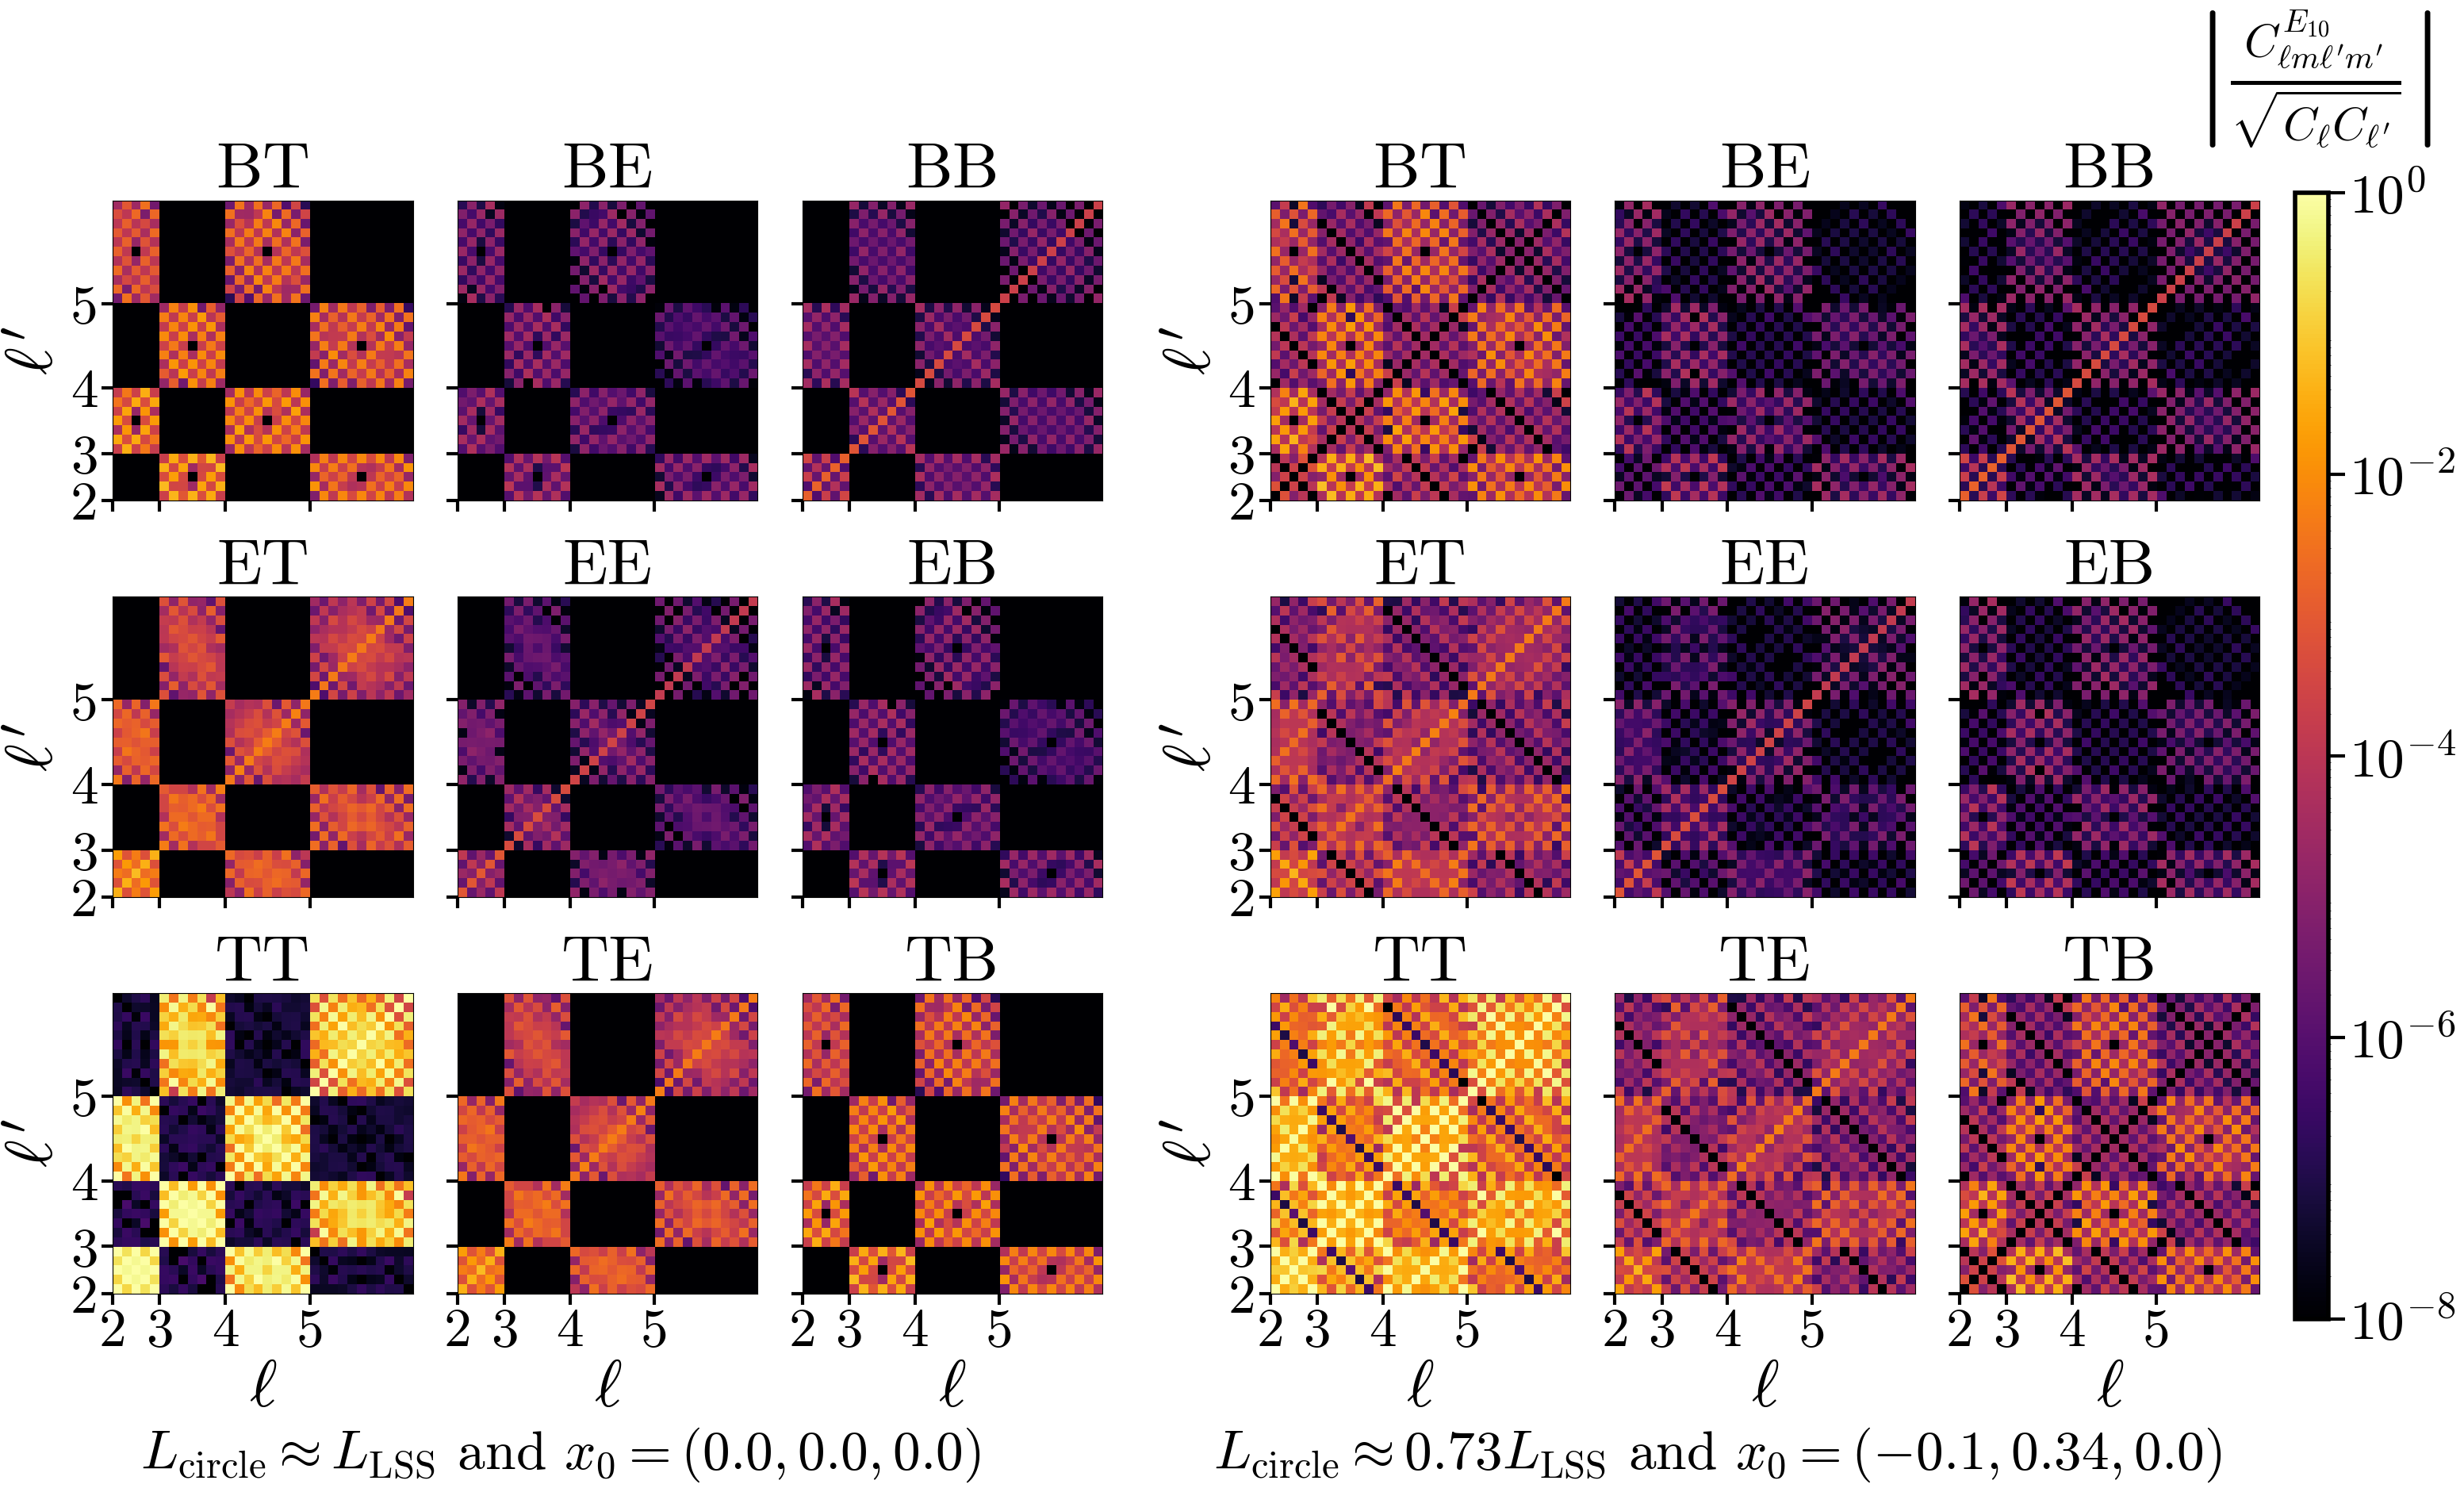

In [9]:
fig = plt.figure(figsize=(32, 17), layout='constrained')
subfig_L, subfig_R,  subfig_C = fig.subfigures(1, 3, wspace=0.05, width_ratios=[1, 1, 0.2])

axL = subfig_L.subplots(3, 3)
axR = subfig_R.subplots(3, 3)

# (title, ax_index, index into c_ell) in the same order as your original calls
panels = [('BT', 5), ('BE', 4), ('BB', 2),
          ('ET', 3), ('EE', 1), ('EB', 4),
          ('TT', 0), ('TE', 3), ('TB', 5)]

for k, (title, c_idx) in enumerate(panels):
    i, j = divmod(k, 3)
    im = do_cov_sub_plot(axL[i, j], normalize=True, title=title, ax_index=k,
                         C_order=c_ell_E7_untilted[c_idx],
                         ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))
    do_cov_sub_plot(axR[i, j], normalize=True, title=title, ax_index=k,
                    C_order=c_ell_E7_tilted[c_idx],   # <- swap in the right-hand dataset
                    ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))

subfig_L.supxlabel(r'$L_{\text{circle}} \approx L_{\text{LSS}}$ and $x_0 = (0.0, 0.0, 0.0)$',
                  fontweight='bold', fontsize=50)
subfig_R.supxlabel(r'$L_{\text{circle}} \approx 0.73 L_{\text{LSS}}$ and $x_0 = (-0.1, 0.34, 0.0)$',
                  fontweight='bold', fontsize=50)

# colorbar axes inside the third subfigure: [left, bottom, width, height] as fractions of subfig_C
cax = subfig_C.add_axes([-0.1, 0.125, 0.15, 0.835])
cbar = subfig_C.colorbar(im, cax=cax)

cbar.ax.set_title(r"$\left| \frac{C^{E_{10}}_{\ell m \ell' m'}}{\sqrt{C_{\ell}C_{\ell'}}} \right|$", fontsize=60, pad=90)
cbar.set_ticks([1e0, 1e-2, 1e-4, 1e-6, 1e-8])
cbar.outline.set_edgecolor('black')
cbar.outline.set_linewidth(4)
cbar.ax.tick_params(which='major', length=15, width=3, labelsize=50)
plt.savefig('plots_E7.pdf', bbox_inches='tight', dpi=400)


NameError: name 'c_ell_E9_untilted' is not defined

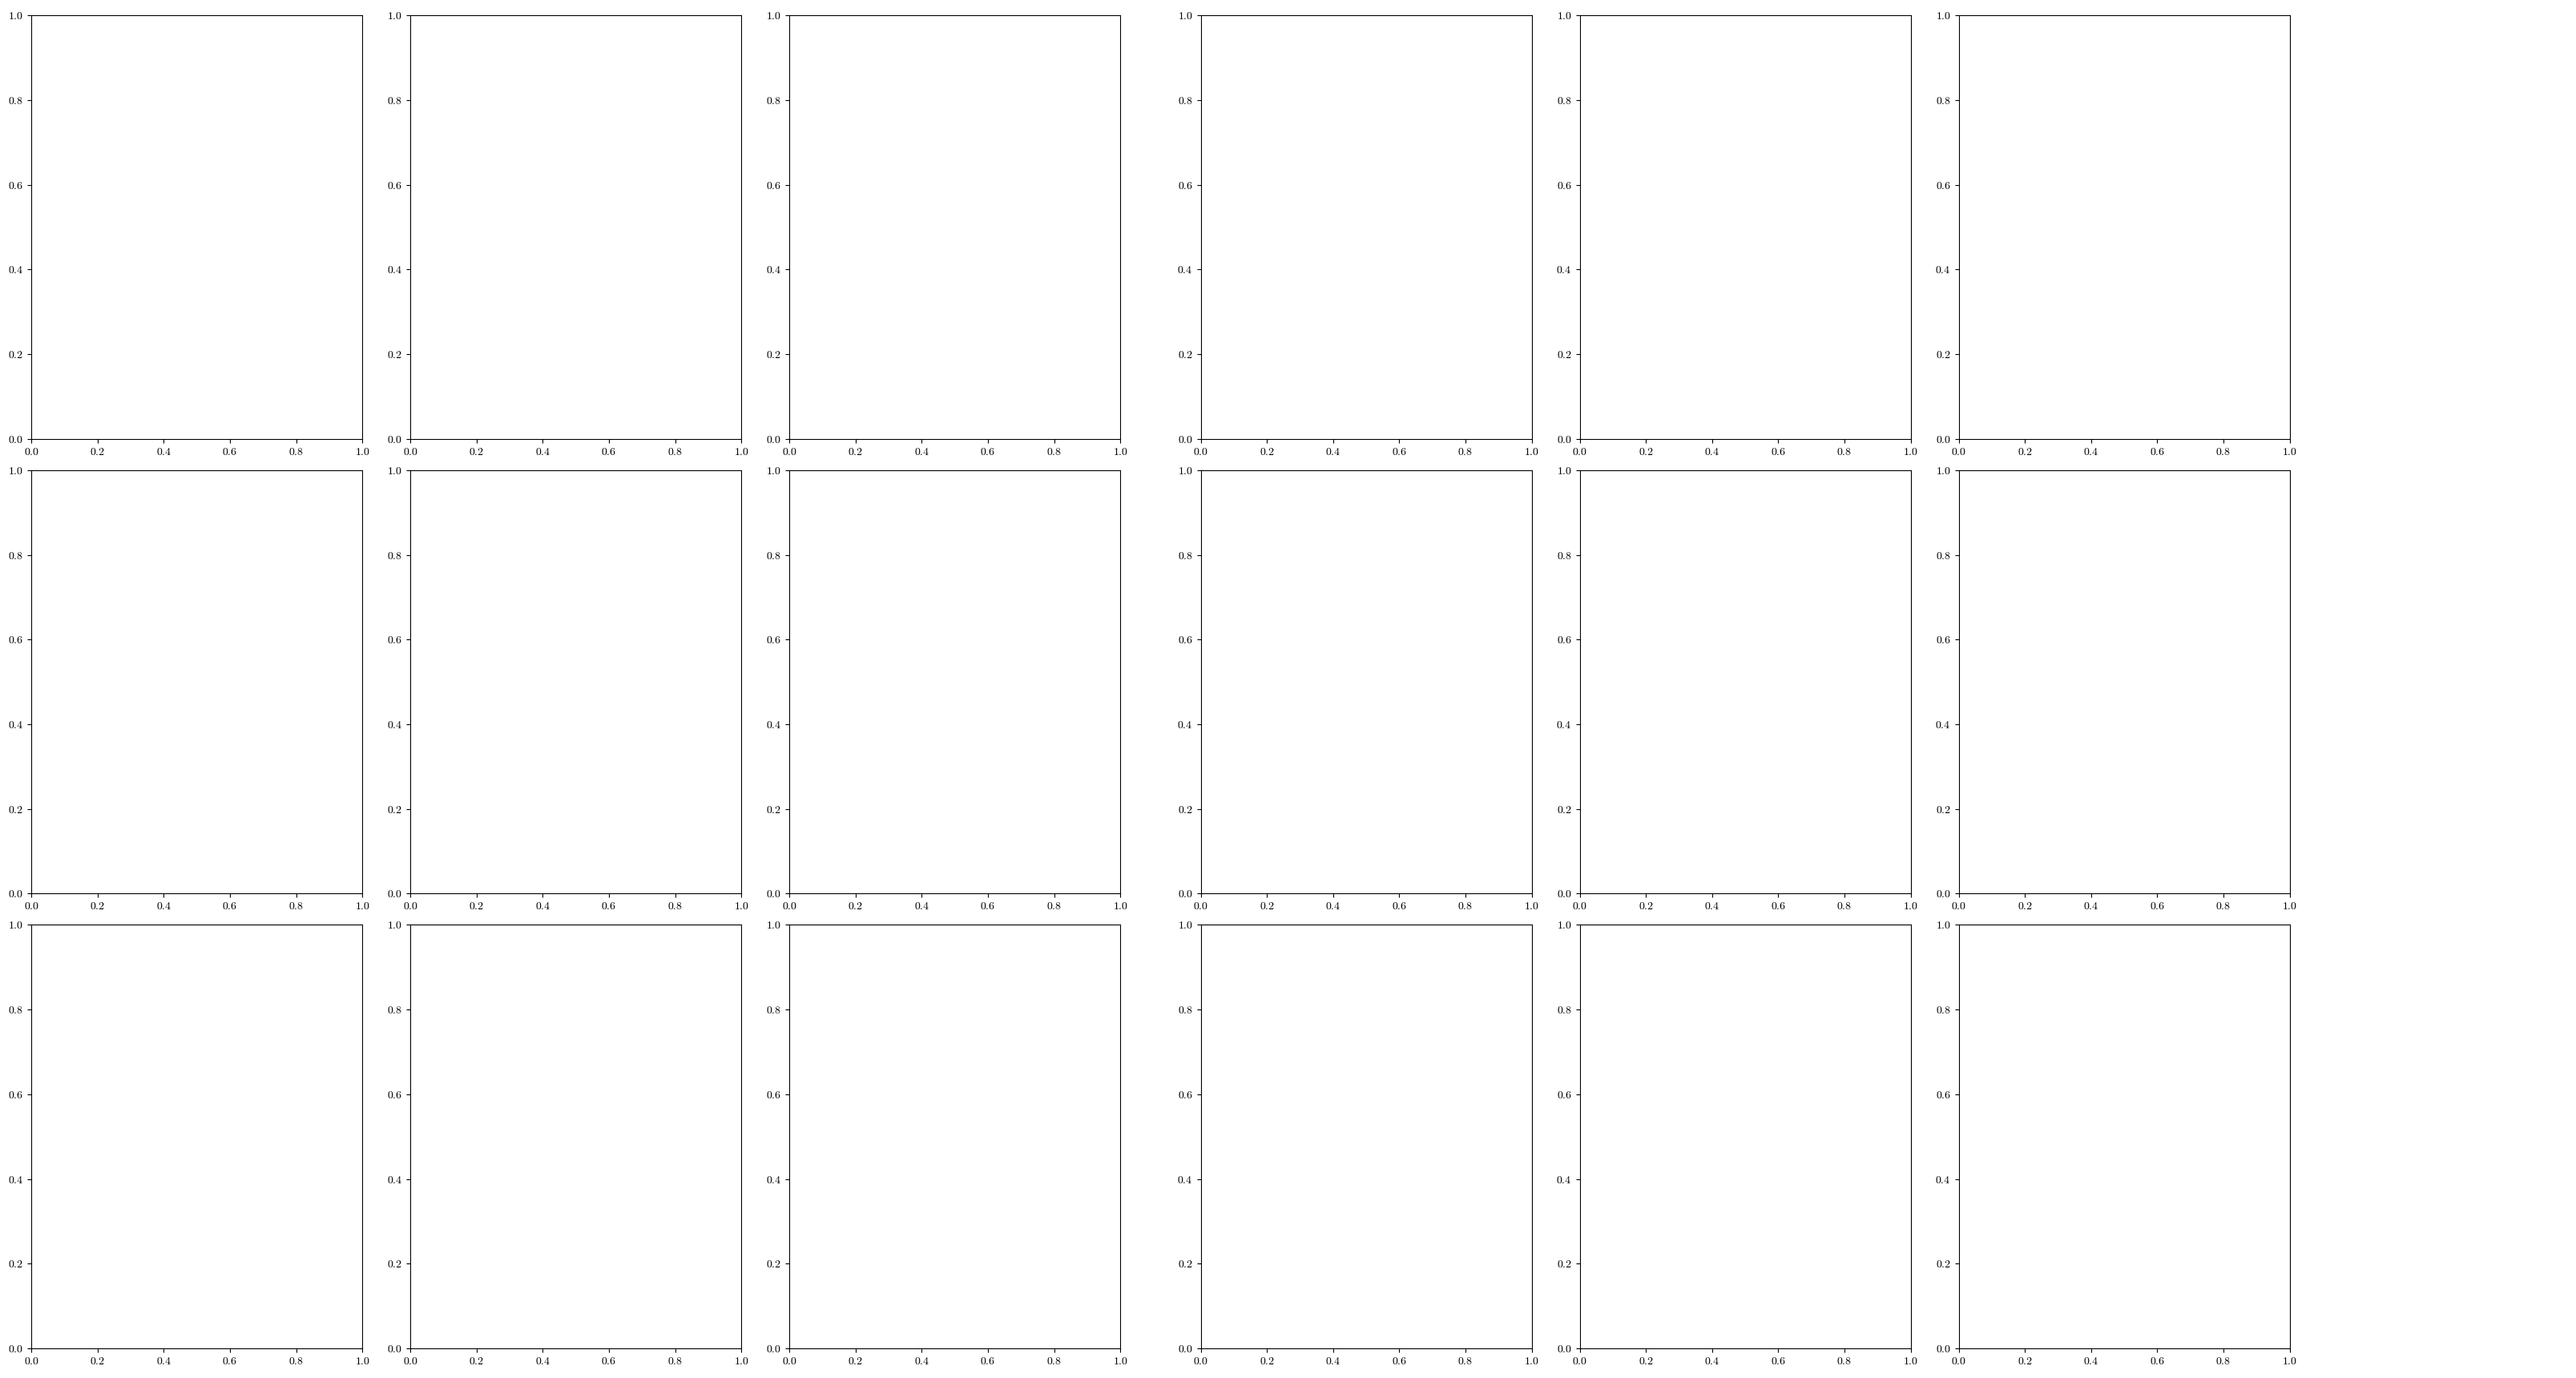

In [6]:
fig = plt.figure(figsize=(32, 17), layout='constrained')
subfig_L, subfig_R,  subfig_C = fig.subfigures(1, 3, wspace=0.05, width_ratios=[1, 1, 0.2])

axL = subfig_L.subplots(3, 3)
axR = subfig_R.subplots(3, 3)

# (title, ax_index, index into c_ell) in the same order as your original calls
panels = [('BT', 5), ('BE', 4), ('BB', 2),
          ('ET', 3), ('EE', 1), ('EB', 4),
          ('TT', 0), ('TE', 3), ('TB', 5)]

for k, (title, c_idx) in enumerate(panels):
    i, j = divmod(k, 3)
    im = do_cov_sub_plot(axL[i, j], normalize=True, title=title, ax_index=k,
                         C_order=c_ell_E9_untilted[c_idx],
                         ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))
    do_cov_sub_plot(axR[i, j], normalize=True, title=title, ax_index=k,
                    C_order=c_ell_E9_tilted[c_idx],   # <- swap in the right-hand dataset
                    ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))

subfig_L.supxlabel(r'$L_{\text{circle}} \approx L_{\text{LSS}}$ and $x_0 = (0.0, 0.0, 0.0)$',
                  fontweight='bold', fontsize=50)
subfig_R.supxlabel(r'$L_{\text{circle}} \approx 0.73 L_{\text{LSS}}$ and $x_0 = (-0.1, 0.34, 0.0)$',
                  fontweight='bold', fontsize=50)

# colorbar axes inside the third subfigure: [left, bottom, width, height] as fractions of subfig_C
cax = subfig_C.add_axes([-0.1, 0.125, 0.15, 0.835])
cbar = subfig_C.colorbar(im, cax=cax)

cbar.ax.set_title(r"$\left| \frac{C^{E_{10}}_{\ell m \ell' m'}}{\sqrt{C_{\ell}C_{\ell'}}} \right|$", fontsize=60, pad=90)
cbar.set_ticks([1e0, 1e-2, 1e-4, 1e-6, 1e-8])
cbar.outline.set_edgecolor('black')
cbar.outline.set_linewidth(4)
cbar.ax.tick_params(which='major', length=15, width=3, labelsize=50)
plt.savefig('plots_E9.pdf', bbox_inches='tight', dpi=400)


# E_8 and E_10

In [79]:
l_max = 5
L_circle = 1

#LAx, LAy, LBx, LBz, LCy
c_ell_E8_untilted = run_topology_E8_10(topology = 'E8', LAx = L_circle, LAy = 0, LBx = 0.7, LBz = 1.0, LCy = 1.4, 
              l_max = l_max, x0= np.array([0.0, 0.0, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

L_circle = 0.73321

c_ell_E8_tilted = run_topology_E8_10(topology = 'E8', LAx = L_circle, LAy = 0, LBx = 0.7, LBz = 1.0, LCy = 1.4, 
              l_max = l_max, x0= np.array([-0.1, 0.34, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

Running - E8 l_max=5_LAx_27649_LAy_0_LBx_19354_LBz_27649_LCy_38709_x_0.00_y_0.00_z_0.00
Running {'topology': 'E8', 'LAx': 1, 'LAy': 0, 'LBx': 0.7, 'LBz': 1.0, 'LCy': 1.4, 'x0': array([0., 0., 0.]), 'c_l_accuracy': 0.99, 'l_max': 5, 'l_min': 2, 'node': 1}
Shape of transfer function from CAMB: (3, 599, 6454)

Finding k_max as a function of ell


100%|██████████| 4/4 [00:00<00:00,  8.89it/s]


Done. k_max for ell_max = 0.01102416508743576
E8 Final num of elements: 682000 Minimum k_amp 0.0001136208093219406 n_x_max 98 n_z_max 98
Time to get list of k, phi, theta: 14.303792953491211 seconds
Getting repeated theta and k elements
Ratio of unique theta: 0.7797316715542522
Ratio of unique |k|: 0.08579472140762463
Time to get unique k and theta: 0.2324221134185791 seconds

Getting transfer functions


100%|██████████| 58512/58512 [00:13<00:00, 4369.69it/s] 


Size of transfer function: 2.68 MB. 


Getting transfer functions


100%|██████████| 58512/58512 [00:07<00:00, 7525.68it/s] 


... (11 outputs left out)

100%|██████████| 72989/72989 [00:03<00:00, 22189.76it/s] 


Size of transfer function: 3.34 MB. 


Getting Wigner_d matrices!


100%|██████████| 408724/408724 [00:17<00:00, 23822.75it/s] 


The Wigner_d metrices array is 112.26 MB 


**************
Done with all preprocessing
**************

Time to pre-process with l_max=5 and accuracy=0.99: 107.48721718788147 seconds

Calculating covariance matrix
Size of integrand: 120.28 MB.
Time to get Correlation functions: 0:0:18


In [2]:
l_max = 5
L_circle = 1

c_ell_E10_untilted = run_topology_E8_10(topology = 'E10', LAx = L_circle, LAy = 0, LBx = 0.7, LBz = 1.0, LCy = 1.4, 
              l_max = l_max, x0= np.array([0.0, 0.0, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

L_circle = 0.73321

c_ell_E10_tilted = run_topology_E8_10(topology = 'E10', LAx = L_circle, LAy = 0, LBx = 0.7, LBz = 1.0, LCy = 1.4, 
              l_max = l_max, x0= np.array([-0.1, 0.34, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

Running - E10 l_max=5_LAx_27649_LAy_0_LBx_19354_LBz_27649_LCy_38709_x_0.00_y_0.00_z_0.00
Running {'topology': 'E10', 'LAx': 1, 'LAy': 0, 'LBx': 0.7, 'LBz': 1.0, 'LCy': 1.4, 'x0': array([0., 0., 0.]), 'c_l_accuracy': 0.99, 'l_max': 5, 'l_min': 2, 'node': 1}
Shape of transfer function from CAMB: (3, 599, 6454)

Finding k_max as a function of ell


100%|██████████| 4/4 [00:00<00:00,  7.75it/s]


Done. k_max for ell_max = 0.01102416508743576
E10 Final num of elements: 682000 Minimum k_amp 0.0001136208093219406 n_x_max 98 n_z_max 98
Time to get list of k, phi, theta: 11.455774307250977 seconds
Getting repeated theta and k elements
Ratio of unique theta: 0.7797316715542522
Ratio of unique |k|: 0.08579472140762463
Time to get unique k and theta: 0.11067605018615723 seconds

Getting transfer functions


100%|██████████| 58512/58512 [00:03<00:00, 16690.83it/s]


Size of transfer function: 2.68 MB. 


Getting transfer functions


100%|██████████| 58512/58512 [00:03<00:00, 18330.16it/s]


... (11 outputs left out)

100%|██████████| 72989/72989 [00:03<00:00, 18616.43it/s] 


Size of transfer function: 3.34 MB. 


Getting Wigner_d matrices!


100%|██████████| 408724/408724 [00:17<00:00, 23883.09it/s] 


The Wigner_d metrices array is 112.26 MB 


**************
Done with all preprocessing
**************

Time to pre-process with l_max=5 and accuracy=0.99: 107.85319781303406 seconds

Calculating covariance matrix
Size of integrand: 120.28 MB.
Time to get Correlation functions: 0:0:22


In [80]:
np.save('c_ell_E8_untilted.npy', c_ell_E8_untilted)
np.save('c_ell_E8_tilted.npy', c_ell_E8_tilted)
np.save('c_ell_E10_untilted.npy', c_ell_E10_untilted)
np.save('c_ell_E10_tilted.npy', c_ell_E10_tilted)


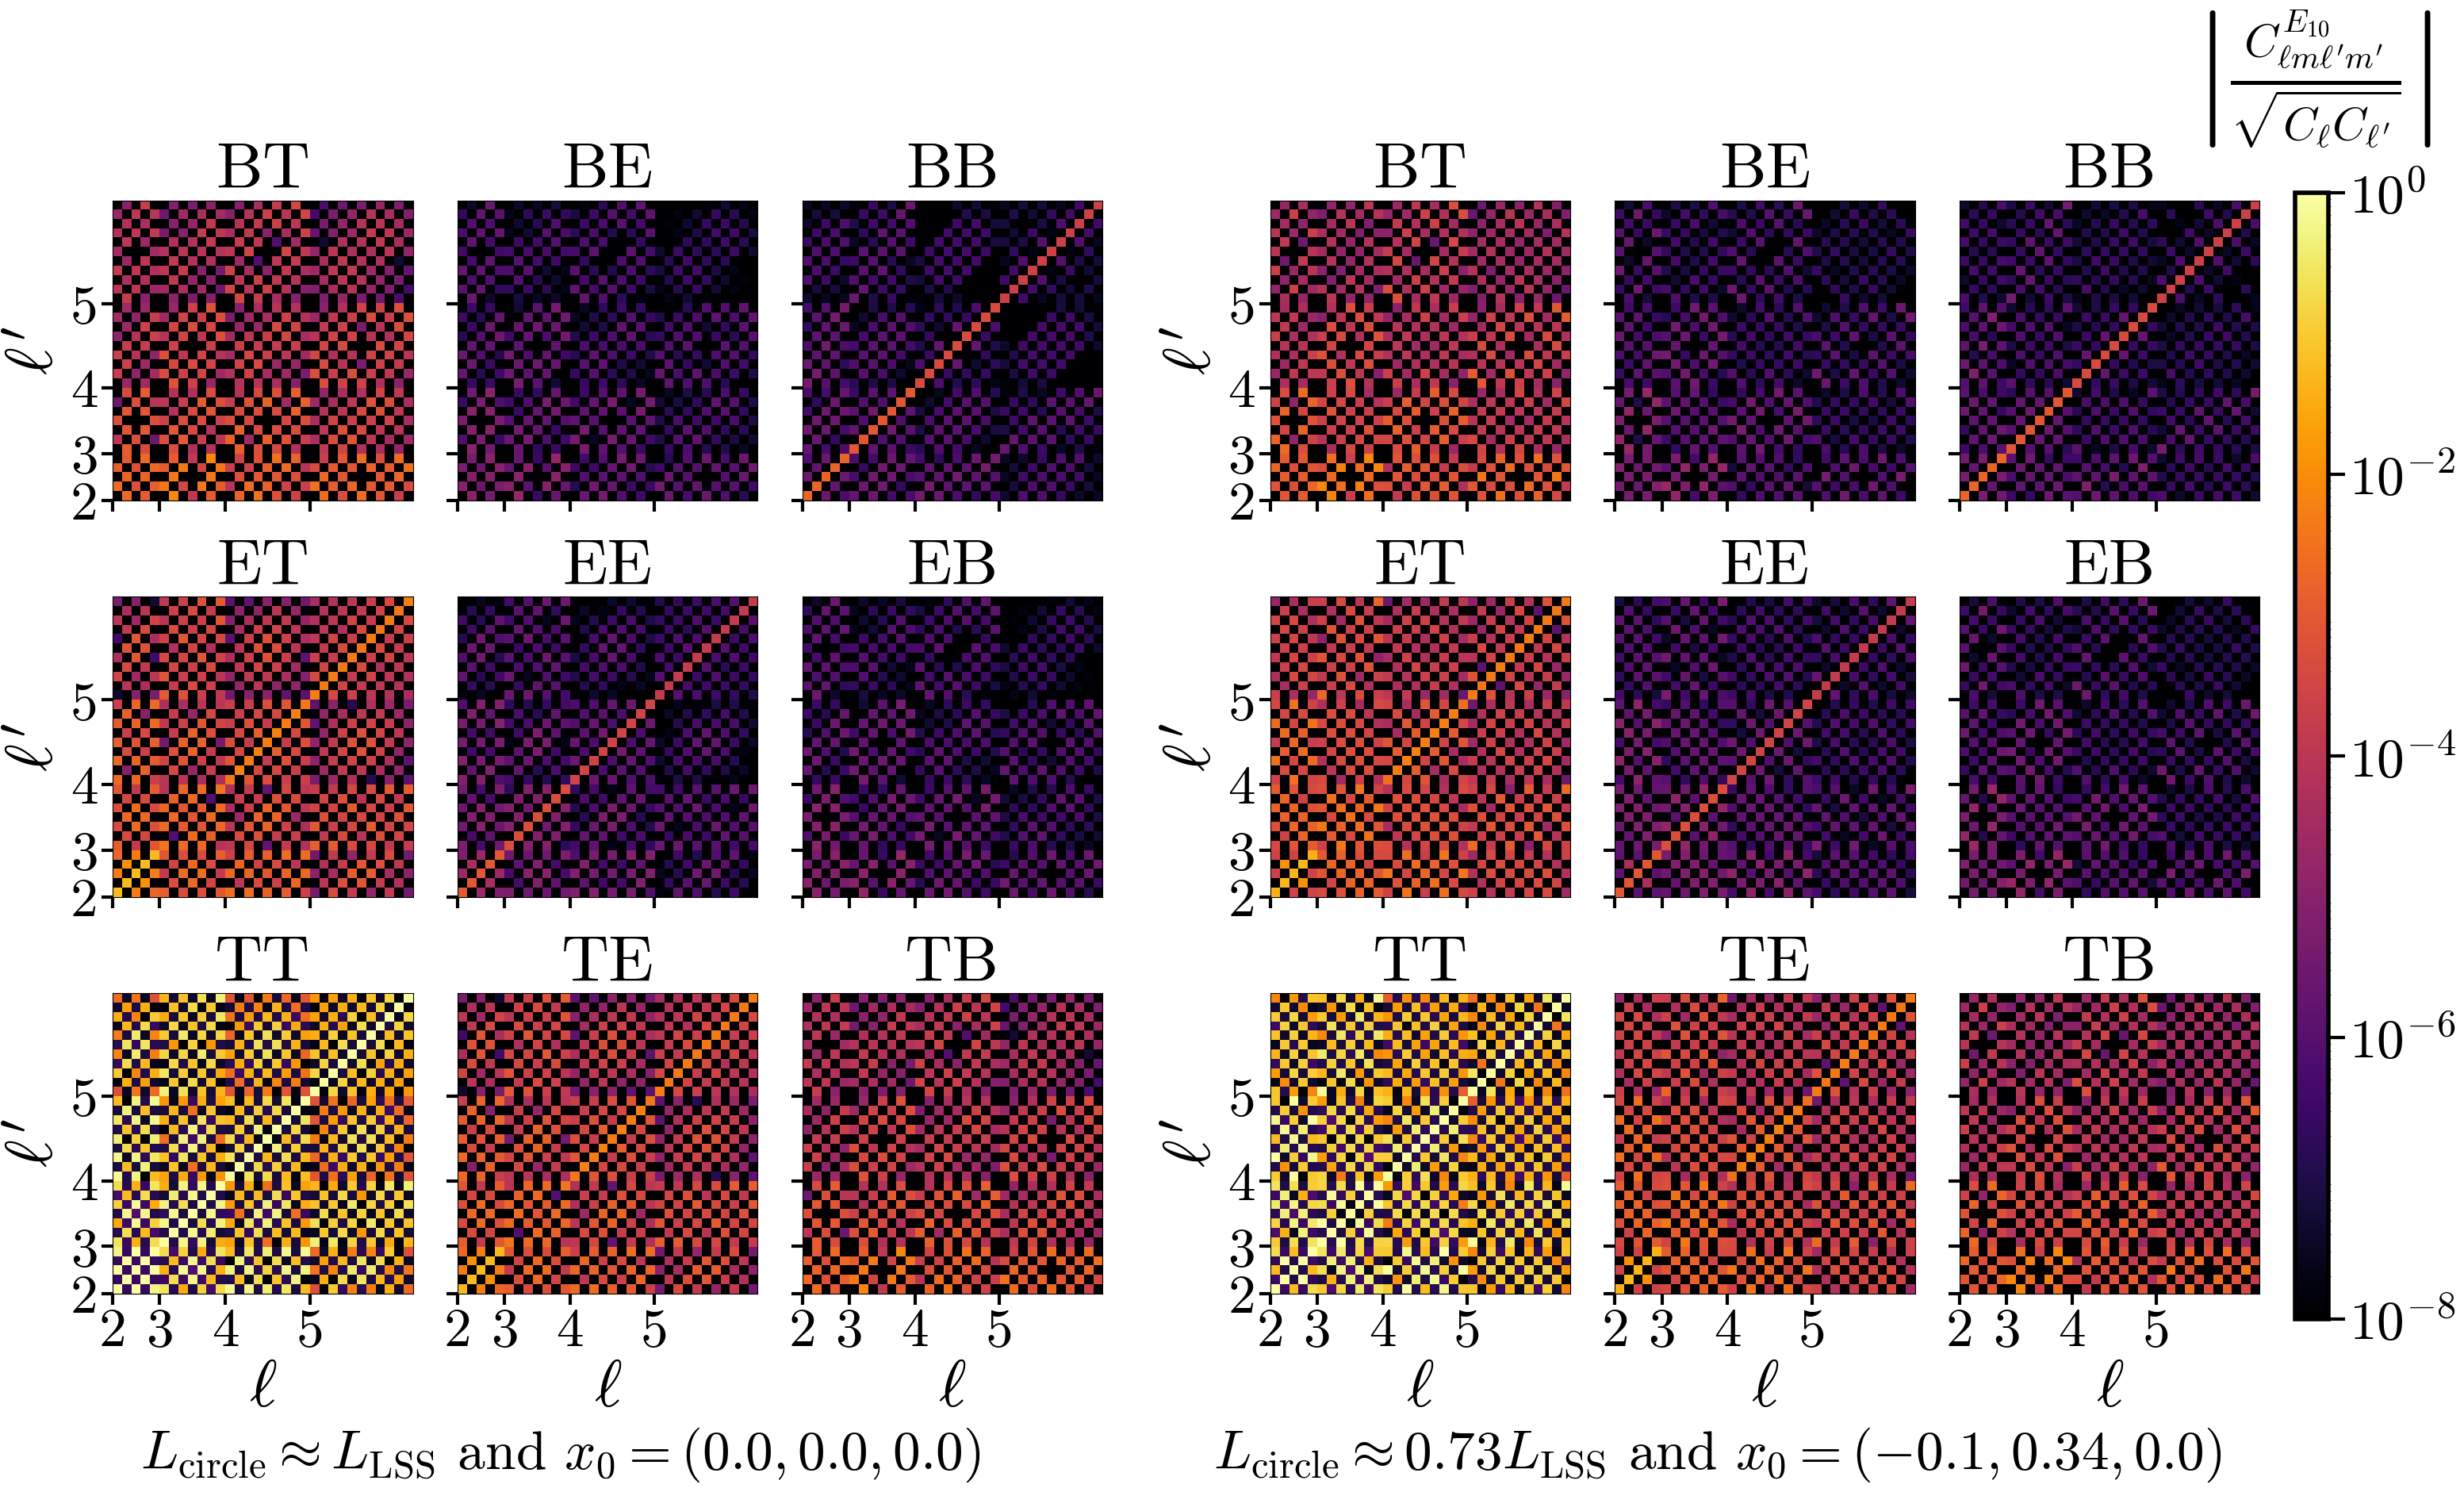

In [81]:
fig = plt.figure(figsize=(32, 17), layout='constrained')
subfig_L, subfig_R,  subfig_C = fig.subfigures(1, 3, wspace=0.05, width_ratios=[1, 1, 0.2])

axL = subfig_L.subplots(3, 3)
axR = subfig_R.subplots(3, 3)

# (title, ax_index, index into c_ell) in the same order as your original calls
panels = [('BT', 5), ('BE', 4), ('BB', 2),
          ('ET', 3), ('EE', 1), ('EB', 4),
          ('TT', 0), ('TE', 3), ('TB', 5)]

for k, (title, c_idx) in enumerate(panels):
    i, j = divmod(k, 3)
    im = do_cov_sub_plot(axL[i, j], normalize=True, title=title, ax_index=k,
                         C_order=c_ell_E8_untilted[c_idx],
                         ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))
    do_cov_sub_plot(axR[i, j], normalize=True, title=title, ax_index=k,
                    C_order=c_ell_E8_tilted[c_idx],   # <- swap in the right-hand dataset
                    ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))

subfig_L.supxlabel(r'$L_{\text{circle}} \approx L_{\text{LSS}}$ and $x_0 = (0.0, 0.0, 0.0)$',
                  fontweight='bold', fontsize=50)
subfig_R.supxlabel(r'$L_{\text{circle}} \approx 0.73 L_{\text{LSS}}$ and $x_0 = (-0.1, 0.34, 0.0)$',
                  fontweight='bold', fontsize=50)

# colorbar axes inside the third subfigure: [left, bottom, width, height] as fractions of subfig_C
cax = subfig_C.add_axes([-0.1, 0.125, 0.15, 0.835])
cbar = subfig_C.colorbar(im, cax=cax)

cbar.ax.set_title(r"$\left| \frac{C^{E_{10}}_{\ell m \ell' m'}}{\sqrt{C_{\ell}C_{\ell'}}} \right|$", fontsize=60, pad=90)
cbar.set_ticks([1e0, 1e-2, 1e-4, 1e-6, 1e-8])
cbar.outline.set_edgecolor('black')
cbar.outline.set_linewidth(4)
cbar.ax.tick_params(which='major', length=15, width=3, labelsize=50)
plt.savefig('plots_E8.pdf', bbox_inches='tight', dpi=400)


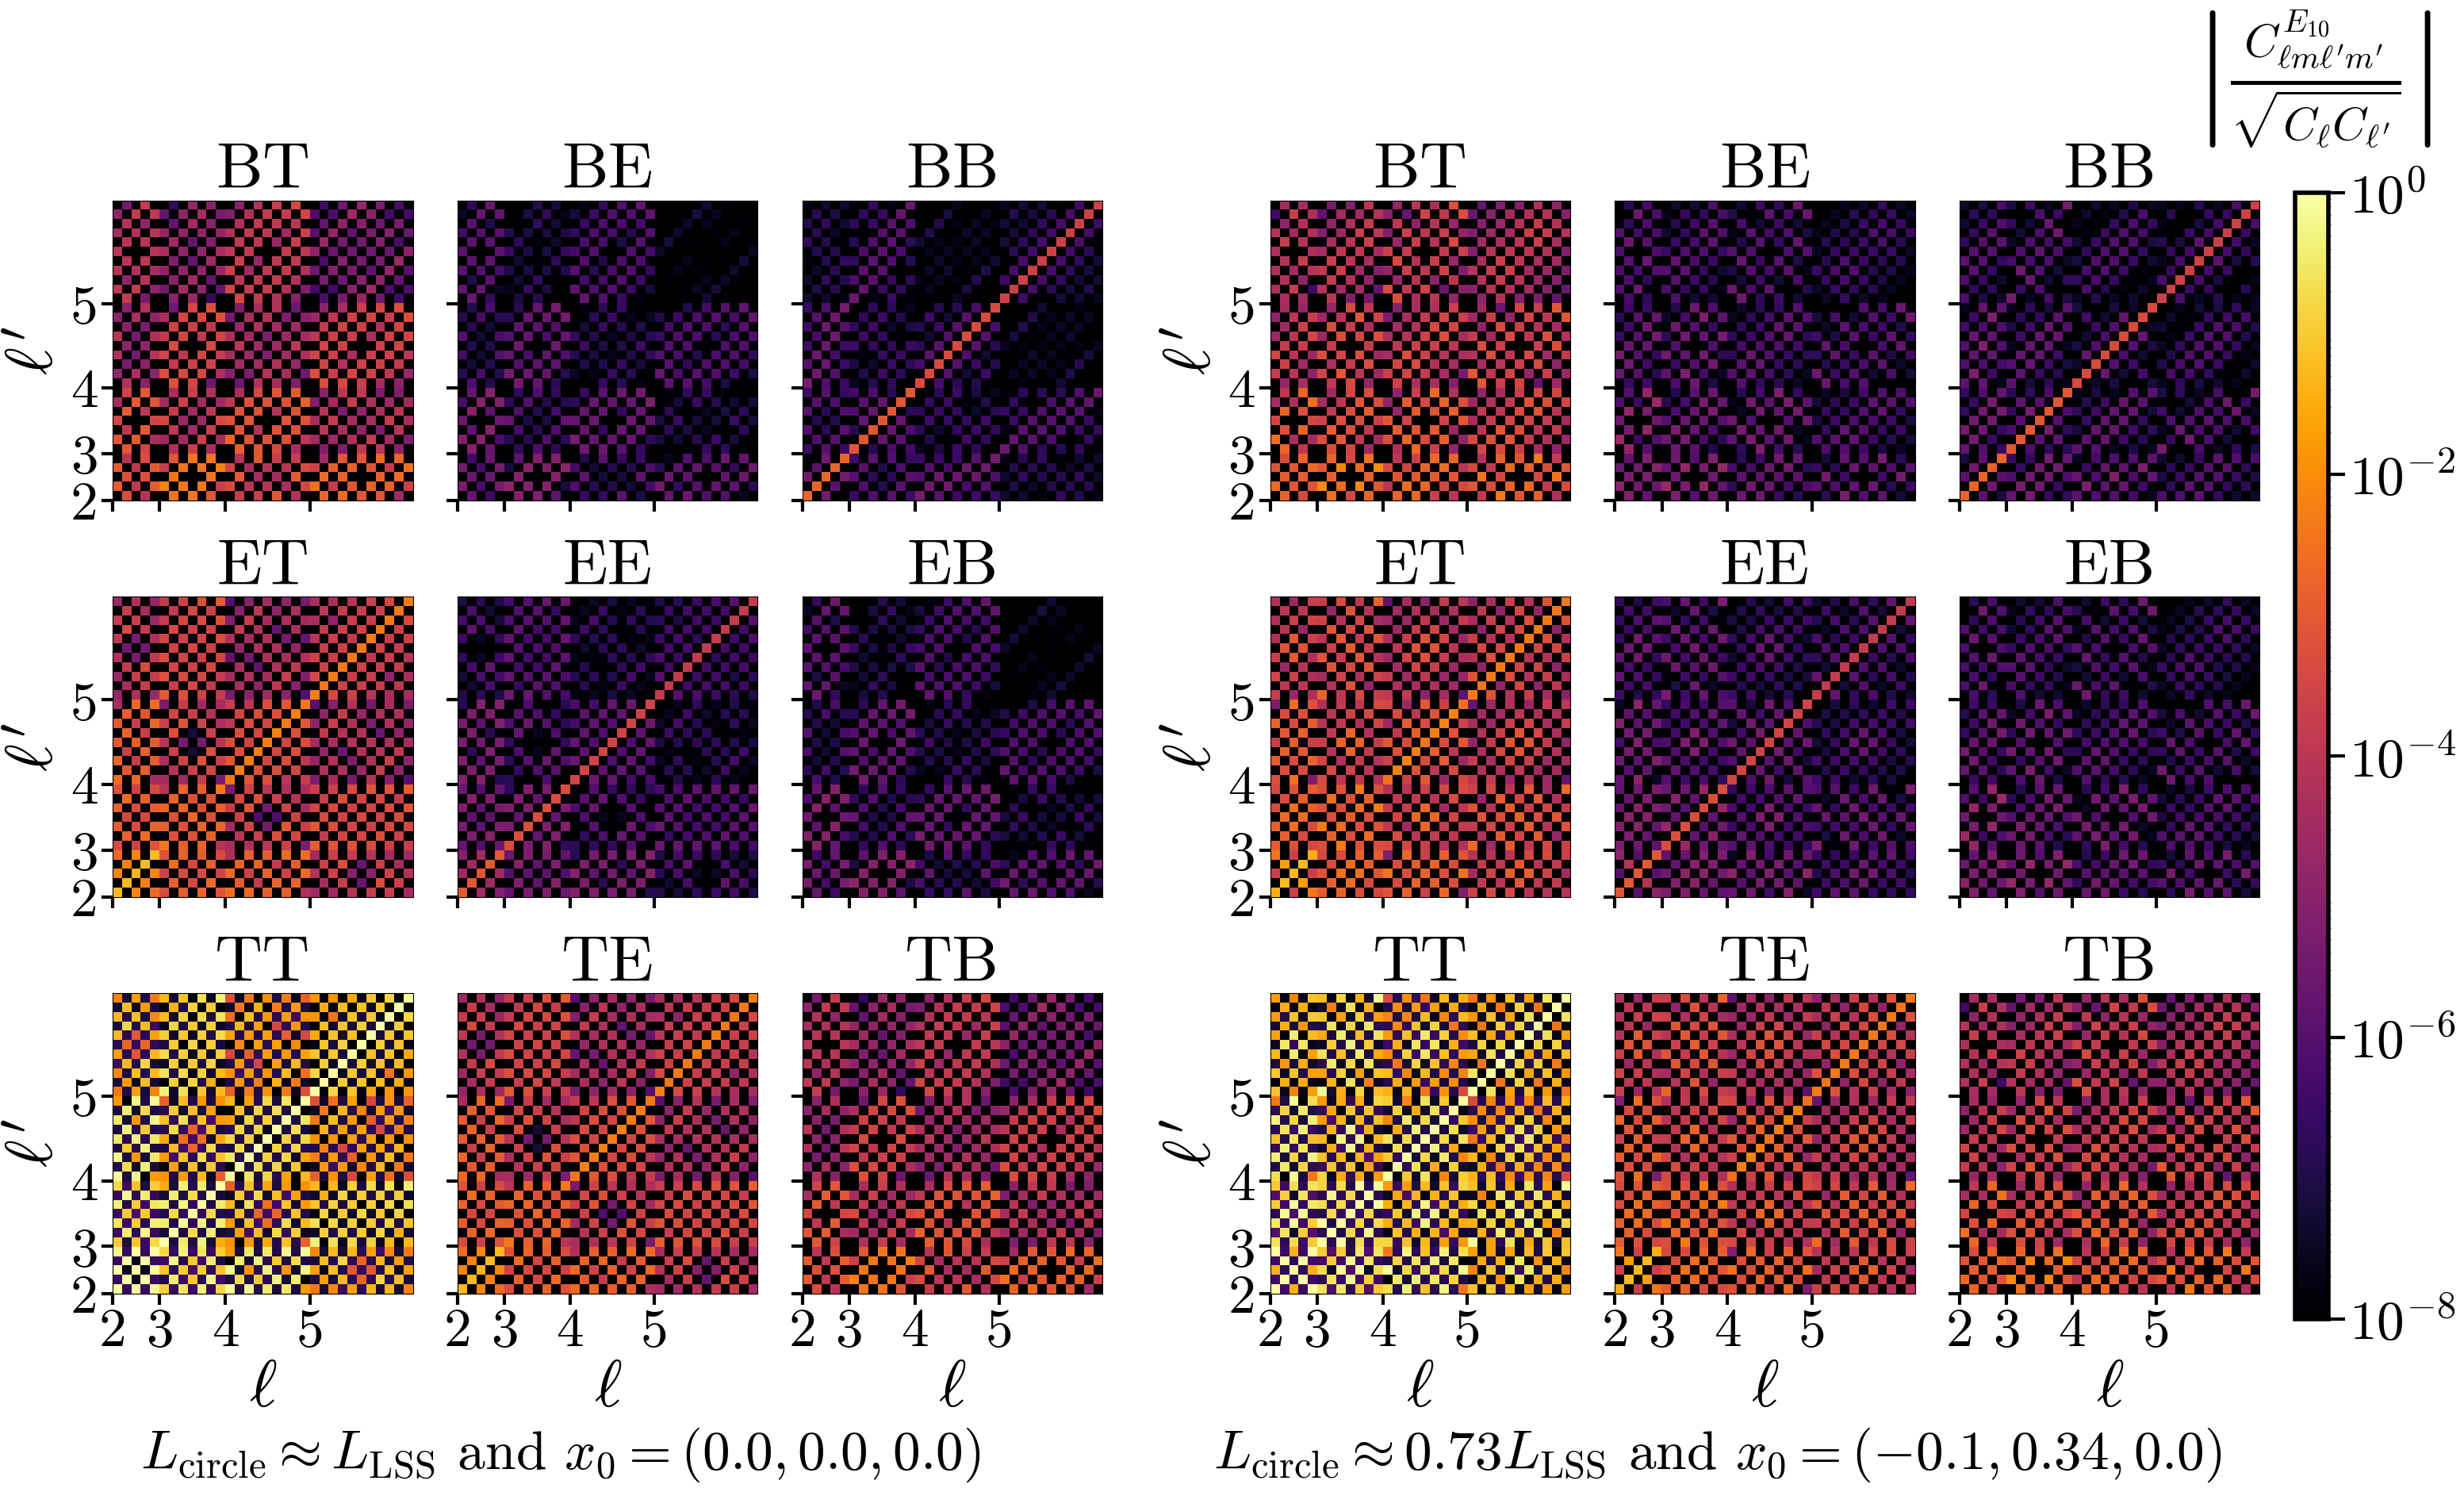

In [3]:
fig = plt.figure(figsize=(32, 17), layout='constrained')
subfig_L, subfig_R,  subfig_C = fig.subfigures(1, 3, wspace=0.05, width_ratios=[1, 1, 0.2])

axL = subfig_L.subplots(3, 3)
axR = subfig_R.subplots(3, 3)

# (title, ax_index, index into c_ell) in the same order as your original calls
panels = [('BT', 5), ('BE', 4), ('BB', 2),
          ('ET', 3), ('EE', 1), ('EB', 4),
          ('TT', 0), ('TE', 3), ('TB', 5)]

for k, (title, c_idx) in enumerate(panels):
    i, j = divmod(k, 3)
    im = do_cov_sub_plot(axL[i, j], normalize=True, title=title, ax_index=k,
                         C_order=c_ell_E10_untilted[c_idx],
                         ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))
    do_cov_sub_plot(axR[i, j], normalize=True, title=title, ax_index=k,
                    C_order=c_ell_E10_tilted[c_idx],   # <- swap in the right-hand dataset
                    ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))

subfig_L.supxlabel(r'$L_{\text{circle}} \approx L_{\text{LSS}}$ and $x_0 = (0.0, 0.0, 0.0)$',
                  fontweight='bold', fontsize=50)
subfig_R.supxlabel(r'$L_{\text{circle}} \approx 0.73 L_{\text{LSS}}$ and $x_0 = (-0.1, 0.34, 0.0)$',
                  fontweight='bold', fontsize=50)

# colorbar axes inside the third subfigure: [left, bottom, width, height] as fractions of subfig_C
cax = subfig_C.add_axes([-0.1, 0.125, 0.15, 0.835])
cbar = subfig_C.colorbar(im, cax=cax)

cbar.ax.set_title(r"$\left| \frac{C^{E_{10}}_{\ell m \ell' m'}}{\sqrt{C_{\ell}C_{\ell'}}} \right|$", fontsize=60, pad=90)
cbar.set_ticks([1e0, 1e-2, 1e-4, 1e-6, 1e-8])
cbar.outline.set_edgecolor('black')
cbar.outline.set_linewidth(4)
cbar.ax.tick_params(which='major', length=15, width=3, labelsize=50)
plt.savefig('plots_E10.pdf', bbox_inches='tight', dpi=400)
